# [IAPR][iapr]: Final project - Chocolate Recognition


**Moodle group ID:** *xx*  
**Kaggle challenge:** *xx* (either `Classic` or `Deep learning`)  
**Kaggle team name (exact):** "*xx*"  

**Author 1 (SCIPER):** *Student Name 1 (xxxxx)*  
**Author 2 (SCIPER):** *Student Name 2 (xxxxx)*  
**Author 3 (SCIPER):** *Student Name 3 (xxxxx)*  

**Due date:** 21.05.2025 (11:59 pm)


## Key Submission Guidelines:
- **Before submitting your notebook, <span style="color:red;">rerun</span> it from scratch!** Go to: `Kernel` > `Restart & Run All`
- **Only groups of three will be accepted**, except in exceptional circumstances.


[iapr]: https://github.com/LTS5/iapr2025

---

> Your comments  
> ...

### Imports :

In [1]:
import os
import sys 
assert (sys.version_info.major == 3) and (sys.version_info.minor == 9)

In [2]:
# if not done yet, install the required packages :
#!pip install -r requirements.txt

In [3]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import mean_absolute_error, r2_score
from tqdm import tqdm
import matplotlib.pyplot as plt
from IPython.display import clear_output

import glob
import re

In [4]:
# I HOPE WE ARE ALLOWED TO USE THIS PACKAGE !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!pip install torchsummary
from torchsummary import summary

### Paths :

In [5]:
dataset_dir = "dataset_project_iapr2025"
images_train_dir = os.path.join(dataset_dir, "train")
images_test_dir = os.path.join(dataset_dir, "test")

train_csv_path = os.path.join(dataset_dir, "train.csv")

In [6]:
dataframe_train = pd.read_csv(train_csv_path)
dataframe_train["filename"] = dataframe_train["id"].apply(lambda x: f"L{x:07d}.JPG")
print(dataframe_train)

         id  Jelly White  Jelly Milk  Jelly Black  Amandina  Crème brulée  \
0   1000756            2           0            0         0             0   
1   1000763            2           3            3         0             0   
2   1000765            0           0            0         0             0   
3   1000768            0           0            0         0             0   
4   1000772            3           2            1         0             0   
..      ...          ...         ...          ...       ...           ...   
85  1010031            0           0            0         0             0   
86  1010032            0           0            0         0             0   
87  1010035            0           0            0         0             0   
88  1010041            0           0            0         2             0   
89  1010045            1           1            1         1             1   

    Triangolo  Tentation noir  Comtesse  Noblesse  Noir authentique  \
0   

In [7]:
def check_image_sizes(image_dir):
    sizes = set()  # set() only keeps unique values
    
    for filename in os.listdir(image_dir):
        if filename.endswith(".JPG"):
            img_path = os.path.join(image_dir, filename)
            image = Image.open(img_path)
            sizes.add(image.size)  # Adds the size (width, height) to the set
    
    if len(sizes) > 1:
        print("Images are of different sizes:")
        print(sizes)
    else:
        print("Every image has the same size :", sizes)

check_image_sizes(images_train_dir)
check_image_sizes(images_test_dir)

Every image has the same size : {(6000, 4000)}
Every image has the same size : {(6000, 4000)}


### Datasets : 2 differents because we have a csv for the training set and we don't for the testing set

In [8]:
class ChocolateTrainDataset(Dataset): # inherits from Dataset class in PyTorch
    def __init__(self, dataframe, images_dir, transform=None):
        self.dataframe = dataframe # dataframe = raw data
        self.images_dir = images_dir # directory where images are stored
        self.transform = transform # transformations to be applied to images
        self.labels = dataframe.iloc[:, 1:-1].values # all columns except the first and last one (id and filename)
        self.filenames = dataframe["filename"].values

    def __len__(self):
        return len(self.dataframe) # number of samples in the dataset

    def __getitem__(self, idx): # will be called each time we iterate over the dataset in a dataloader
        img_name = os.path.join(self.images_dir, self.filenames[idx])
        image = Image.open(img_name).convert("RGB")
        if self.transform:
            image = self.transform(image) # will be applied each time we iterate over the dataset in a dataloader
        
        label = torch.tensor(self.labels[idx], dtype=torch.float32)  # 13 classes
        return image, label
    
class ChocolateTestDataset(Dataset):
    def __init__(self, images_dir, transform=None):
        self.images_dir = images_dir
        self.transform = transform
        self.image_paths = sorted(glob.glob(os.path.join(images_dir, "*.JPG"))) # does not have a csv/dataframe like the training dataset => need to find the filenames by ourselves

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image


In [9]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Create the train dataset and dataloader WITHOUT normalization
train_dataset = ChocolateTrainDataset(dataframe_train, images_train_dir, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=15, shuffle=True)


# Create the test dataset and dataloader WITHOUT normalization
test_dataset = ChocolateTestDataset(images_test_dir, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=15, shuffle=False)

In [10]:
def calculate_mean_std(dataloader):
    means = []
    stds = []
    for batch in dataloader: # enable to handle train_loader and test_loader
        if isinstance(batch, (list, tuple)): # batch is a tuple (images, labels) for train_loader
            images = batch[0]  # (images, labels)
        else: # batch is a tensor for test_loader
            images = batch  # (images,)
        means.append(torch.mean(images, dim=[0, 2, 3])) # size of the image is (batch_size, channels, height, width) => mean for each channel (RGB), output is (3,)
        stds.append(torch.std(images, dim=[0, 2, 3])) # std for each channel (RGB)
    
    mean = torch.mean(torch.stack(means), dim=0).numpy()
    std = torch.mean(torch.stack(stds), dim=0).numpy()
    return mean, std




# Calculate mean and std with the dataloader
mean_train, std_train = calculate_mean_std(train_loader)

print(f"Mean train: {mean_train}")
print(f"Std train: {std_train}")

transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_train, std=std_train)
])

# Recreate the train dataset and dataloader WITH its normalization
train_dataset = ChocolateTrainDataset(dataframe_train, images_train_dir, transform=transform_train)
train_loader = DataLoader(train_dataset, batch_size=15, shuffle=True)



# Calculate mean and std with the dataloader
mean_test, std_test = calculate_mean_std(test_loader)

print(f"Mean test: {mean_test}")
print(f"Std test: {std_test}")

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_test, std=std_test)
])

# Recreate the test dataset and dataloader WITH its normalization
test_dataset = ChocolateTestDataset(images_test_dir, transform=transform_test)
test_loader = DataLoader(test_dataset, batch_size=15, shuffle=False)

Mean train: [0.6840921  0.6594279  0.65269655]
Std train: [0.16889204 0.16640122 0.19070028]
Mean test: [0.68614024 0.66012734 0.65339464]
Std test: [0.16177155 0.16175413 0.18529408]


### CNN : MAYBE WE NEED TO USE ATTENTION GATED POOLING LIKE LAB 3 ???????????????????????? Also maybe initialize the weights like in DL

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class ChocolateCounterCNN(nn.Module):
    def __init__(self):
        super(ChocolateCounterCNN, self).__init__() # call the constructor of the parent class nn.Module
        
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), # 3 channels (RGB) -> 16 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 224x224 pixels to 112x112

            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 channels -> 32 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 112x112 pixels to 56x56

            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 32 channels -> 64 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 56x56 pixels to 28x28

            nn.Conv2d(64, 128, kernel_size=3, padding=1), # 64 channels -> 128 channels
            nn.ReLU(),
            nn.MaxPool2d(2), # from 28x28 pixels to 14x14
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(), # flatten the output of the conv layers
            nn.Linear(128 * 14 * 14, 512), # 128 channels * (14*14) pixels to 512 neurons
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 13)  # 13 types of chocolates
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

In [12]:
actual_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ChocolateCounterCNN().to(actual_device)  # <- modèle sur GPU

summary(model, (3, 224, 224), device = actual_device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 224, 224]             448
              ReLU-2         [-1, 16, 224, 224]               0
         MaxPool2d-3         [-1, 16, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]           4,640
              ReLU-5         [-1, 32, 112, 112]               0
         MaxPool2d-6           [-1, 32, 56, 56]               0
            Conv2d-7           [-1, 64, 56, 56]          18,496
              ReLU-8           [-1, 64, 56, 56]               0
         MaxPool2d-9           [-1, 64, 28, 28]               0
           Conv2d-10          [-1, 128, 28, 28]          73,856
             ReLU-11          [-1, 128, 28, 28]               0
        MaxPool2d-12          [-1, 128, 14, 14]               0
           Conv2d-13          [-1, 128, 14, 14]         147,584
             ReLU-14          [-1, 128,

## From practise 3 DL :

In [13]:
def mae(preds, target):
    return mean_absolute_error(target, preds)

def r2(preds, target):
    return r2_score(target, preds)


def train_epoch(model, optimizer, criterion, metrics, train_loader, device):
    
    # we activate the training state for the model
    model.train()

    # initialize epoch loss and metrics
    epoch_loss = 0
    epoch_metrics = dict(zip(metrics.keys(), torch.zeros(len(metrics))))

    # we iterate over the batches
    for batch_num, (x_batch, y_batch) in tqdm(enumerate(train_loader)):
        data = x_batch.to(device) # (batch_size, channels, height, width)
        target = y_batch.to(device) #Le terme device dans PyTorch fait référence à l'appareil (CPU ou GPU) sur lequel les tenseurs et les modèles sont stockés et exécutés.

        # Clean previously computed gradients
        optimizer.zero_grad()
        
        # Forward pass
        output = model(data) #calcule les prédictions du modèle. (scores bruts, pas encore les argmax)

        # Compute loss
        loss = criterion(output, target)

        # Compute gradients and optimize the model parameters
        loss.backward() #calcule les gradients
        optimizer.step() #met à jour les paramètres du modèle.
        
        '''
        Compute predictions and metrics
        Store predictions in variable preds
        No gradients should be propagated at this step
        '''
        with torch.no_grad(): #Cela garantit que PyTorch n'enregistre pas les opérations associées à torch.max() dans le graphe computationnel, ce qui évite une consommation mémoire excessive et optimise l'entraînement.
            preds = output.detach().cpu()
            target = target.detach().cpu()
            for k in epoch_metrics.keys():
                epoch_metrics[k] += metrics[k](preds, target)


        # log loss statistics
        epoch_loss += loss.item()

    # for the epoch loss, we take the average of the losses computed over the mini-batches
    epoch_loss /= len(train_loader)

    # for the epoch loss, we compute the average of the metrics over the mini-batches
    for k in epoch_metrics.keys():
          epoch_metrics[k] /= len(train_loader)

    clear_output() #clean the prints from previous epochs
    print('train Loss: {:.4f}, '.format(epoch_loss),
          ', '.join(['{}: {:.4f}'.format(k, epoch_metrics[k]) for k in epoch_metrics.keys()]))

    return epoch_loss,  epoch_metrics


In [14]:
def plot_training(train_loss, metrics_names, train_metrics_logs):
    fig, ax = plt.subplots(1, len(metrics_names) + 1, figsize=((len(metrics_names) + 1) * 5, 5))

    ax[0].plot(train_loss, c='blue', label='train')
    ax[0].set_title('Loss')
    ax[0].set_xlabel('epoch')
    ax[0].legend()

    for i in range(len(metrics_names)):
        ax[i + 1].plot(train_metrics_logs[i], c='blue', label='train')
        ax[i + 1].set_title(metrics_names[i])
        ax[i + 1].set_xlabel('epoch')
        ax[i + 1].legend()

    plt.show()

def update_metrics_log(metrics_names, metrics_log, new_metrics_dict):
    '''
    - metrics_names: the keys/names of the logged metrics
    - metrics_log: existing metrics log that will be updated
    - new_metrics_dict: epoch_metrics output from train_epoch and evaluate functions
    '''
    for i in range(len(metrics_names)):
        curr_metric_name = metrics_names[i]
        metrics_log[i].append(new_metrics_dict[curr_metric_name])
    return metrics_log

In [15]:
def train_cycle(model, optimizer, criterion, metrics, train_loader, n_epochs, device):
    train_loss_log = []
    metrics_names = list(metrics.keys())
    train_metrics_log = [[] for _ in range(len(metrics))]

    for epoch in range(n_epochs):
        print(f"Epoch {epoch+1} / {n_epochs}")
        train_loss, train_metrics = train_epoch(model, optimizer, criterion, metrics, train_loader, device)

        train_loss_log.append(train_loss)
        train_metrics_log = update_metrics_log(metrics_names, train_metrics_log, train_metrics)

        plot_training(train_loss_log, metrics_names, train_metrics_log)

    return train_metrics_log


train Loss: 0.9024,  MAE: 0.5274, R²: -0.3113


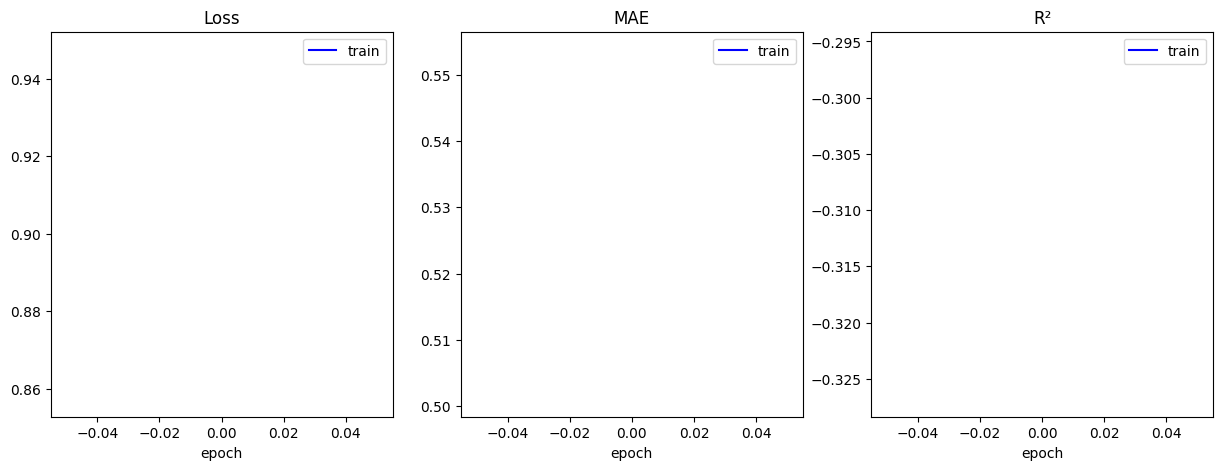

In [ ]:
torch.manual_seed(42)

model = ChocolateCounterCNN()

metrics = {'MAE': mae, 'R²': r2}


#optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4) # or lr=1e-3

criterion = nn.MSELoss()  # or nn.L1Loss() if we want to be more robust to outliers

N_EPOCHS = 30
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device}")

model.to(device)
criterion.to(device)

train_metrics_log = train_cycle(model, optimizer, criterion, metrics, train_loader=train_loader, n_epochs=N_EPOCHS, device=device)

# save model weights
results_models_weights_dir = 'models_weights/'
if not os.path.exists(results_models_weights_dir):
    os.mkdir(results_models_weights_dir)
torch.save(model.state_dict(), results_models_weights_dir + 'base_model.pth')

### Create predictions csv :

In [19]:
# Liste des noms de chocolat dans l'ordre (doit être le même que dans les labels)
chocolate_names = [
    "Jelly White", "Jelly Milk", "Jelly Black",
    "Amandina", "Crème brulée", "Triangolo",
    "Tentation noir", "Comtesse", "Noblesse",
    "Noir authentique", "Passion au lait", "Arabia",
    "Stracciatella"
]

def generate_predictions_csv(model, test_loader, device, output_path="submission.csv"):
    model.eval()
    predictions = []
    image_ids = []

    with torch.no_grad():
        for batch_idx, x_batch in tqdm(enumerate(test_loader)):

            x_batch = x_batch.to(device)
            outputs = model(x_batch)
            outputs = torch.round(outputs).cpu().numpy().astype(int)

            # Récupération des noms ou IDs d'images depuis le dataset
            # Ici, on suppose que test_loader.dataset.samples[i][0] contient le chemin
            batch_size = outputs.shape[0]
            print("batch_size", batch_size)
            for i in range(batch_size):
                # Exemple : extrait "1000756" de ".../1000756.jpg"
                path = test_loader.dataset.image_paths[batch_idx * test_loader.batch_size + i]
                print("path", path)
                image_id_str = os.path.splitext(os.path.basename(path))[0]  # 'L1000757'
                image_id = int(re.sub(r'\D', '', image_id_str))  # Enlève les caractères non numériques
                print("image_id", image_id)
                image_ids.append(image_id)
                predictions.append(outputs[i])

    # Création du DataFrame
    df = pd.DataFrame(predictions, columns=chocolate_names)
    df.insert(0, "id", image_ids)
    df.to_csv(output_path, index=False)
    print(f"✅ CSV enregistré : {output_path}")


In [20]:
# Assure-toi que le modèle est en mode évaluation et chargé sur le bon appareil
model.to(actual_device)

# Appelle la fonction
generate_predictions_csv(model, test_loader, actual_device)

1it [00:07,  7.95s/it]

batch_size 15
path dataset_project_iapr2025\test\L1000757.JPG
image_id 1000757
path dataset_project_iapr2025\test\L1000758.JPG
image_id 1000758
path dataset_project_iapr2025\test\L1000759.JPG
image_id 1000759
path dataset_project_iapr2025\test\L1000760.JPG
image_id 1000760
path dataset_project_iapr2025\test\L1000761.JPG
image_id 1000761
path dataset_project_iapr2025\test\L1000762.JPG
image_id 1000762
path dataset_project_iapr2025\test\L1000764.JPG
image_id 1000764
path dataset_project_iapr2025\test\L1000766.JPG
image_id 1000766
path dataset_project_iapr2025\test\L1000767.JPG
image_id 1000767
path dataset_project_iapr2025\test\L1000769.JPG
image_id 1000769
path dataset_project_iapr2025\test\L1000770.JPG
image_id 1000770
path dataset_project_iapr2025\test\L1000773.JPG
image_id 1000773
path dataset_project_iapr2025\test\L1000774.JPG
image_id 1000774
path dataset_project_iapr2025\test\L1000775.JPG
image_id 1000775
path dataset_project_iapr2025\test\L1000776.JPG
image_id 1000776


2it [00:15,  7.48s/it]

batch_size 15
path dataset_project_iapr2025\test\L1000777.JPG
image_id 1000777
path dataset_project_iapr2025\test\L1000778.JPG
image_id 1000778
path dataset_project_iapr2025\test\L1000781.JPG
image_id 1000781
path dataset_project_iapr2025\test\L1000782.JPG
image_id 1000782
path dataset_project_iapr2025\test\L1000783.JPG
image_id 1000783
path dataset_project_iapr2025\test\L1000784.JPG
image_id 1000784
path dataset_project_iapr2025\test\L1000786.JPG
image_id 1000786
path dataset_project_iapr2025\test\L1000789.JPG
image_id 1000789
path dataset_project_iapr2025\test\L1000790.JPG
image_id 1000790
path dataset_project_iapr2025\test\L1000794.JPG
image_id 1000794
path dataset_project_iapr2025\test\L1000795.JPG
image_id 1000795
path dataset_project_iapr2025\test\L1000796.JPG
image_id 1000796
path dataset_project_iapr2025\test\L1000798.JPG
image_id 1000798
path dataset_project_iapr2025\test\L1000800.JPG
image_id 1000800
path dataset_project_iapr2025\test\L1000801.JPG
image_id 1000801


3it [00:21,  6.90s/it]

batch_size 15
path dataset_project_iapr2025\test\L1000806.JPG
image_id 1000806
path dataset_project_iapr2025\test\L1000807.JPG
image_id 1000807
path dataset_project_iapr2025\test\L1000809.JPG
image_id 1000809
path dataset_project_iapr2025\test\L1000811.JPG
image_id 1000811
path dataset_project_iapr2025\test\L1000813.JPG
image_id 1000813
path dataset_project_iapr2025\test\L1000814.JPG
image_id 1000814
path dataset_project_iapr2025\test\L1000816.JPG
image_id 1000816
path dataset_project_iapr2025\test\L1000818.JPG
image_id 1000818
path dataset_project_iapr2025\test\L1000819.JPG
image_id 1000819
path dataset_project_iapr2025\test\L1000822.JPG
image_id 1000822
path dataset_project_iapr2025\test\L1000823.JPG
image_id 1000823
path dataset_project_iapr2025\test\L1000824.JPG
image_id 1000824
path dataset_project_iapr2025\test\L1000825.JPG
image_id 1000825
path dataset_project_iapr2025\test\L1000829.JPG
image_id 1000829
path dataset_project_iapr2025\test\L1000830.JPG
image_id 1000830


... (14 outputs left out)

11it [01:10,  6.03s/it]

batch_size 15
path dataset_project_iapr2025\test\L1010001.JPG
image_id 1010001
path dataset_project_iapr2025\test\L1010002.JPG
image_id 1010002
path dataset_project_iapr2025\test\L1010003.JPG
image_id 1010003
path dataset_project_iapr2025\test\L1010005.JPG
image_id 1010005
path dataset_project_iapr2025\test\L1010006.JPG
image_id 1010006
path dataset_project_iapr2025\test\L1010007.JPG
image_id 1010007
path dataset_project_iapr2025\test\L1010010.JPG
image_id 1010010
path dataset_project_iapr2025\test\L1010011.JPG
image_id 1010011
path dataset_project_iapr2025\test\L1010016.JPG
image_id 1010016
path dataset_project_iapr2025\test\L1010018.JPG
image_id 1010018
path dataset_project_iapr2025\test\L1010020.JPG
image_id 1010020
path dataset_project_iapr2025\test\L1010021.JPG
image_id 1010021
path dataset_project_iapr2025\test\L1010023.JPG
image_id 1010023
path dataset_project_iapr2025\test\L1010024.JPG
image_id 1010024
path dataset_project_iapr2025\test\L1010025.JPG
image_id 1010025


12it [01:15,  6.32s/it]

batch_size 15
path dataset_project_iapr2025\test\L1010027.JPG
image_id 1010027
path dataset_project_iapr2025\test\L1010028.JPG
image_id 1010028
path dataset_project_iapr2025\test\L1010030.JPG
image_id 1010030
path dataset_project_iapr2025\test\L1010033.JPG
image_id 1010033
path dataset_project_iapr2025\test\L1010034.JPG
image_id 1010034
path dataset_project_iapr2025\test\L1010036.JPG
image_id 1010036
path dataset_project_iapr2025\test\L1010037.JPG
image_id 1010037
path dataset_project_iapr2025\test\L1010038.JPG
image_id 1010038
path dataset_project_iapr2025\test\L1010039.JPG
image_id 1010039
path dataset_project_iapr2025\test\L1010040.JPG
image_id 1010040
path dataset_project_iapr2025\test\L1010042.JPG
image_id 1010042
path dataset_project_iapr2025\test\L1010043.JPG
image_id 1010043
path dataset_project_iapr2025\test\L1010044.JPG
image_id 1010044
path dataset_project_iapr2025\test\L1010046.JPG
image_id 1010046
path dataset_project_iapr2025\test\L1010047.JPG
image_id 1010047
✅ CSV enreg